# Анализ успеваемости студентов

Здесь представлен код из `main.py`, разбитый на ячейки. Каждый график выводится в отдельной ячейке.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", palette="deep")

df = pd.read_csv("StudentsPerformance.csv")

In [2]:
print("Размер набора данных:", df.shape)
print("Первые пять строк:")
print(df.head())
print("Структура данных:")
df.info()
print("Основные статистические характеристики:")
print(df.describe())
print("Количество пропусков по столбцам:")
print(df.isnull().sum())
print("Количестeво уникальных значений по столбцам:")
print(df.nunique())

Размер набора данных: (1000, 8)
Первые пять строк:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
Структура данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (tot

In [3]:
num_cols = df.select_dtypes(include="number").columns

q1 = df["math score"].quantile(0.25)
q3 = df["math score"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = df[(df["math score"] < lower) | (df["math score"] > upper)]
print("Границы выбросов для math score:", round(lower, 2), "и", round(upper, 2))
print("Количество выбросов:", len(outliers))
print(outliers[["math score", "reading score", "writing score"]])

Границы выбросов для math score: 27.0 и 107.0
Количество выбросов: 8
     math score  reading score  writing score
17           18             32             28
59            0             17             10
145          22             39             33
338          24             38             27
466          26             31             38
787          19             38             32
842          23             44             36
980           8             24             23


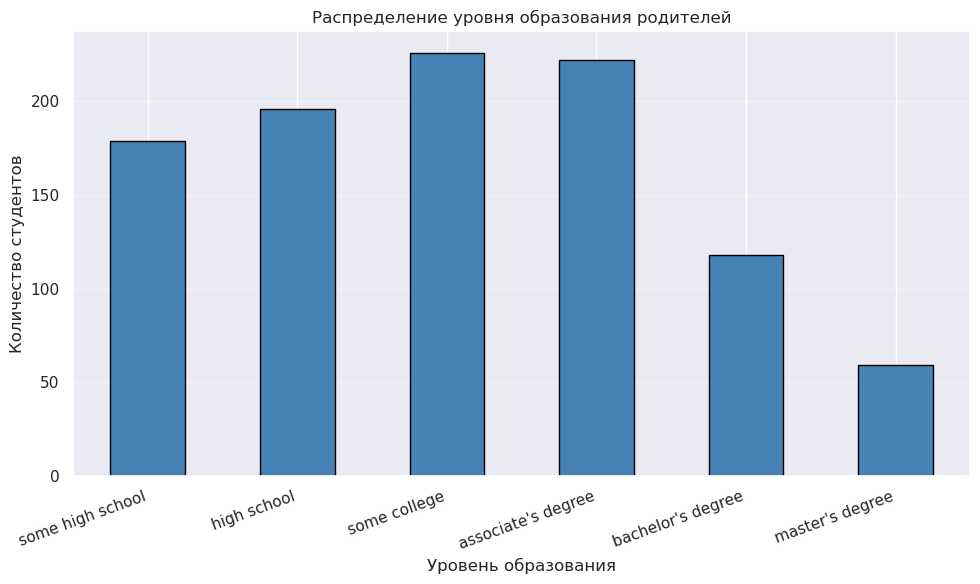

In [4]:
education_order = [
    "some high school",
    "high school",
    "some college",
    "associate's degree",
    "bachelor's degree",
    "master's degree",
]
education_counts = df["parental level of education"].value_counts().reindex(education_order)
education_counts.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black",
    figsize=(10, 6),
)
plt.title("Распределение уровня образования родителей")
plt.xlabel("Уровень образования")
plt.ylabel("Количество студентов")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

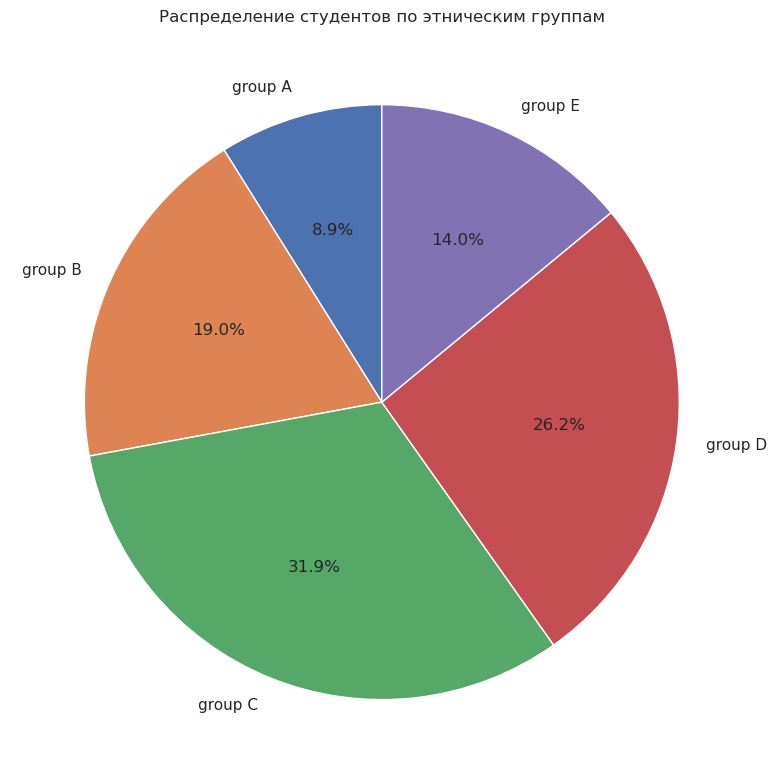

In [5]:
race_counts = df["race/ethnicity"].value_counts().sort_index()
race_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    figsize=(8, 8),
    ylabel="",
)
plt.title("Распределение студентов по этническим группам")
plt.tight_layout()
plt.show()

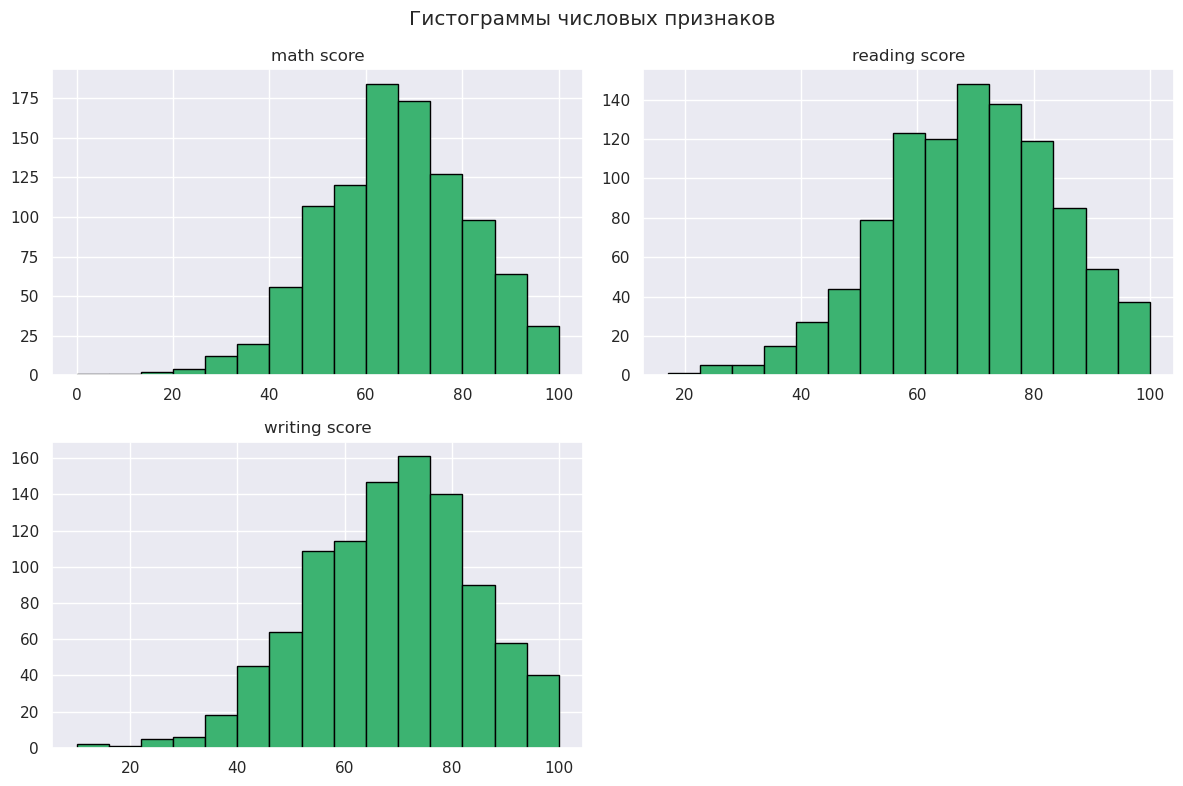

In [6]:
df[num_cols].hist(figsize=(12, 8), color="mediumseagreen", edgecolor="black", bins=15)
plt.suptitle("Гистограммы числовых признаков")
plt.tight_layout()
plt.show()

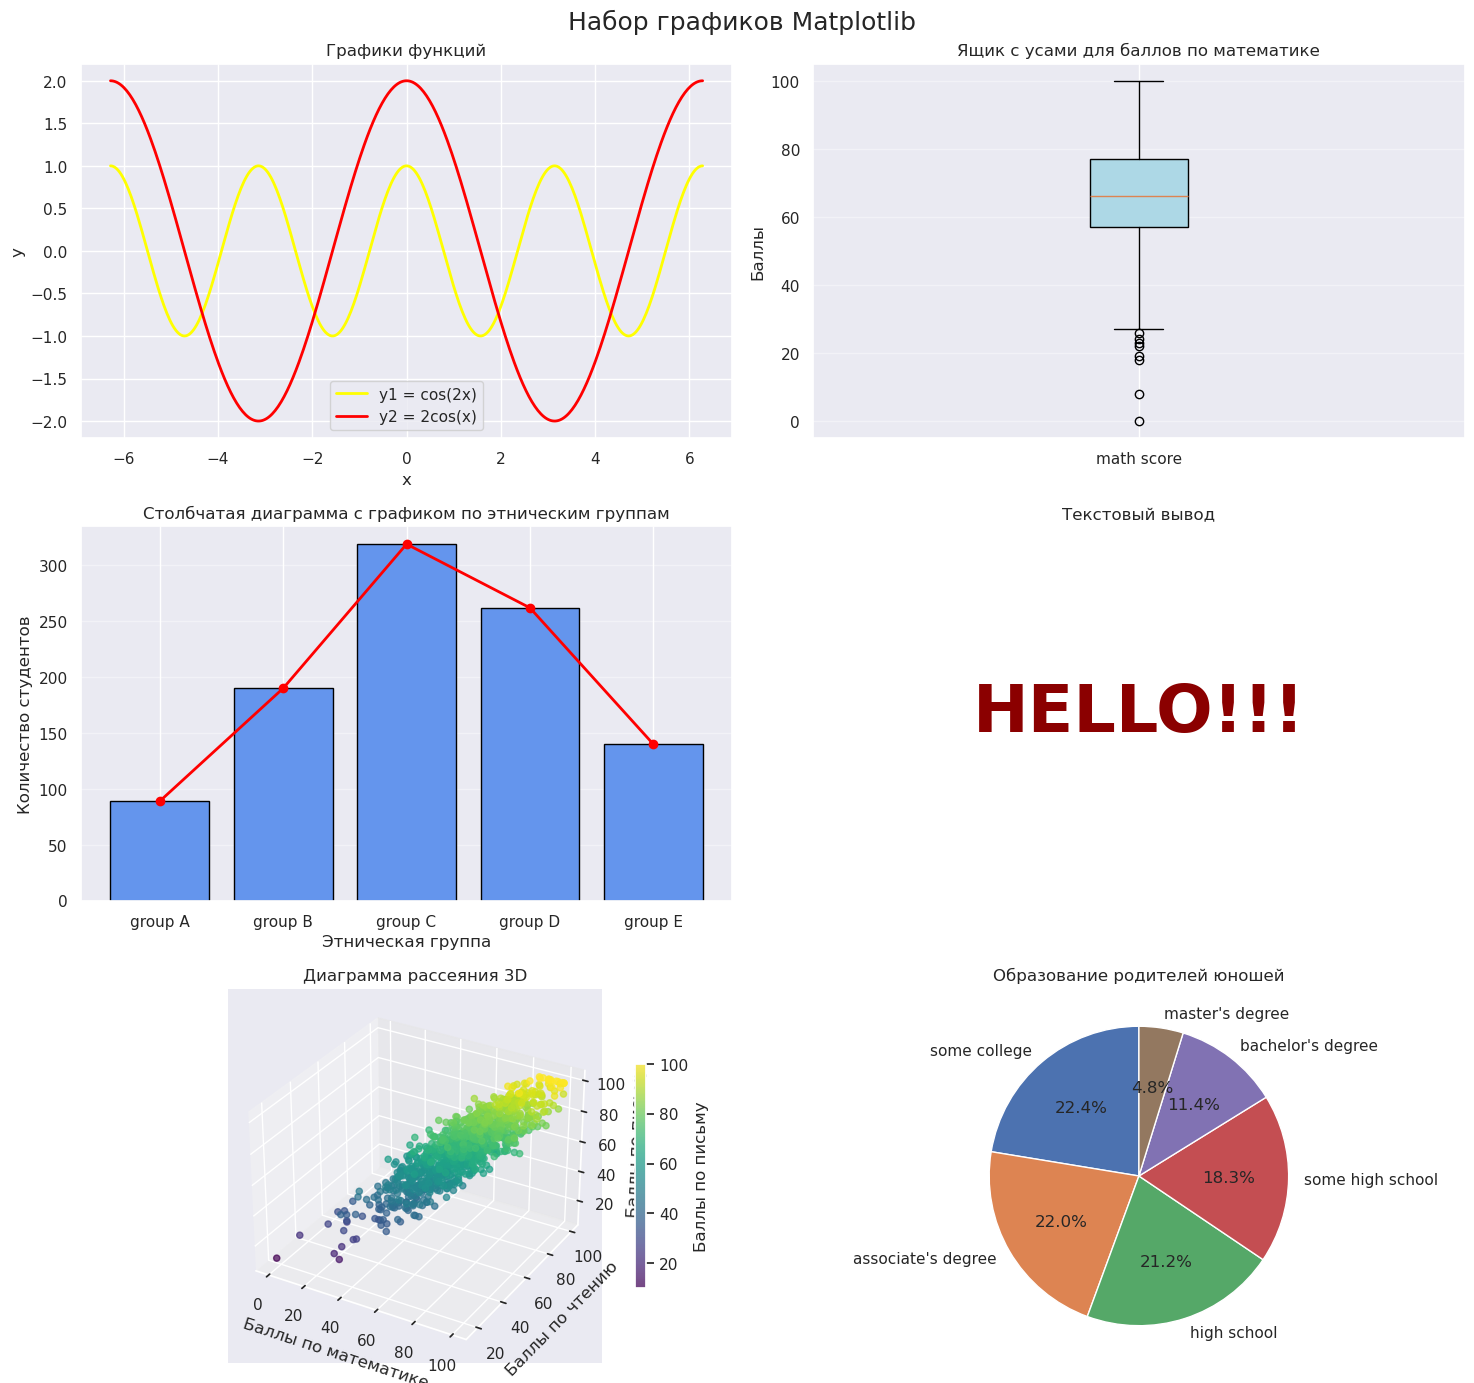

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

x = np.linspace(-2 * np.pi, 2 * np.pi, 400)
axes[0, 0].plot(x, np.cos(2 * x), color="yellow", linewidth=2, label="y1 = cos(2x)")
axes[0, 0].plot(x, 2 * np.cos(x), color="red", linewidth=2, label="y2 = 2cos(x)")
axes[0, 0].set_title("Графики функций")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("y")
axes[0, 0].grid(True)
axes[0, 0].legend()

axes[0, 1].boxplot(df["math score"], patch_artist=True, boxprops=dict(facecolor="lightblue"))
axes[0, 1].set_title("Ящик с усами для баллов по математике")
axes[0, 1].set_ylabel("Баллы")
axes[0, 1].set_xticks([1])
axes[0, 1].set_xticklabels(["math score"])
axes[0, 1].grid(axis="y", alpha=0.4)

axes[1, 0].bar(race_counts.index, race_counts.values, color="cornflowerblue", edgecolor="black")
axes[1, 0].plot(race_counts.index, race_counts.values, color="red", marker="o", linewidth=2)
axes[1, 0].set_title("Столбчатая диаграмма с графиком по этническим группам")
axes[1, 0].set_xlabel("Этническая группа")
axes[1, 0].set_ylabel("Количество студентов")
axes[1, 0].grid(axis="y", alpha=0.4)

axes[1, 1].text(
    0.5,
    0.5,
    "HELLO!!!",
    fontsize=48,
    fontweight="bold",
    ha="center",
    va="center",
    color="darkred",
)
axes[1, 1].set_title("Текстовый вывод")
axes[1, 1].axis("off")

axes[2, 0].remove()
ax3d = fig.add_subplot(3, 2, 5, projection="3d")
scatter = ax3d.scatter(
    df["math score"],
    df["reading score"],
    df["writing score"],
    c=df["writing score"],
    cmap="viridis",
    alpha=0.7,
)
ax3d.set_title("Диаграмма рассеяния 3D")
ax3d.set_xlabel("Баллы по математике")
ax3d.set_ylabel("Баллы по чтению")
ax3d.set_zlabel("Баллы по письму")
fig.colorbar(scatter, ax=ax3d, shrink=0.6, label="Баллы по письму")

male_counts = df[df["gender"] == "male"]["parental level of education"].value_counts()
axes[2, 1].pie(male_counts.values, labels=male_counts.index, autopct="%1.1f%%", startangle=90)
axes[2, 1].set_title("Образование родителей юношей")

fig.suptitle("Набор графиков Matplotlib", fontsize=18)
plt.tight_layout()
plt.show()

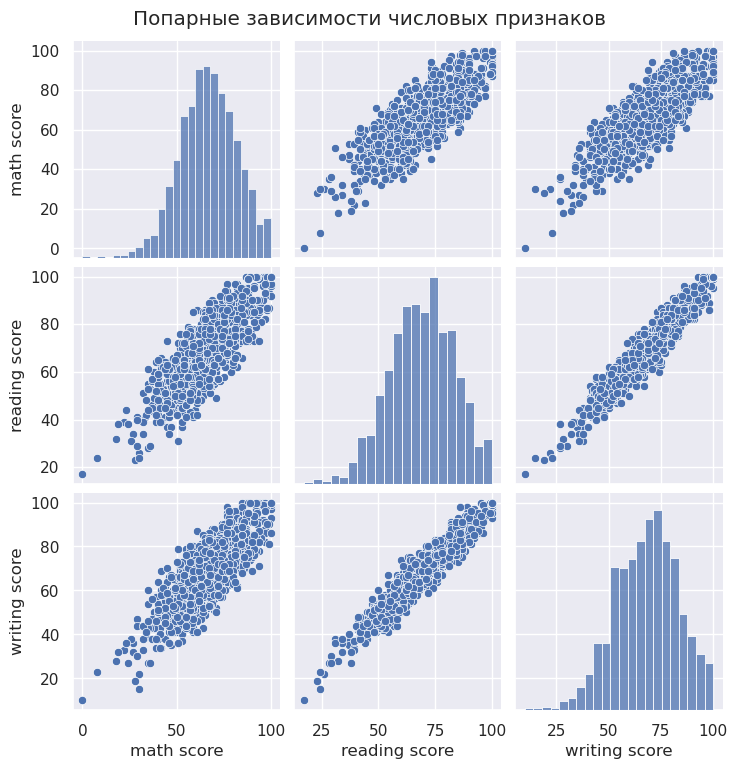

In [8]:
sns.pairplot(df[num_cols])
plt.suptitle("Попарные зависимости числовых признаков", y=1.02)
plt.show()

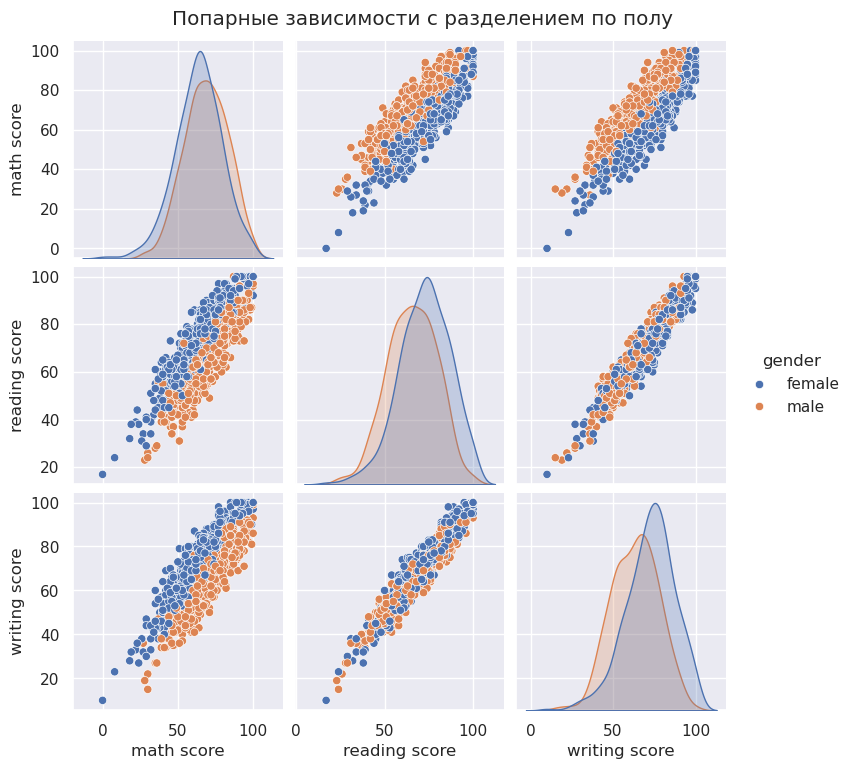

In [9]:
sns.pairplot(df, vars=list(num_cols), hue="gender", diag_kind="kde")
plt.suptitle("Попарные зависимости с разделением по полу", y=1.02)
plt.show()

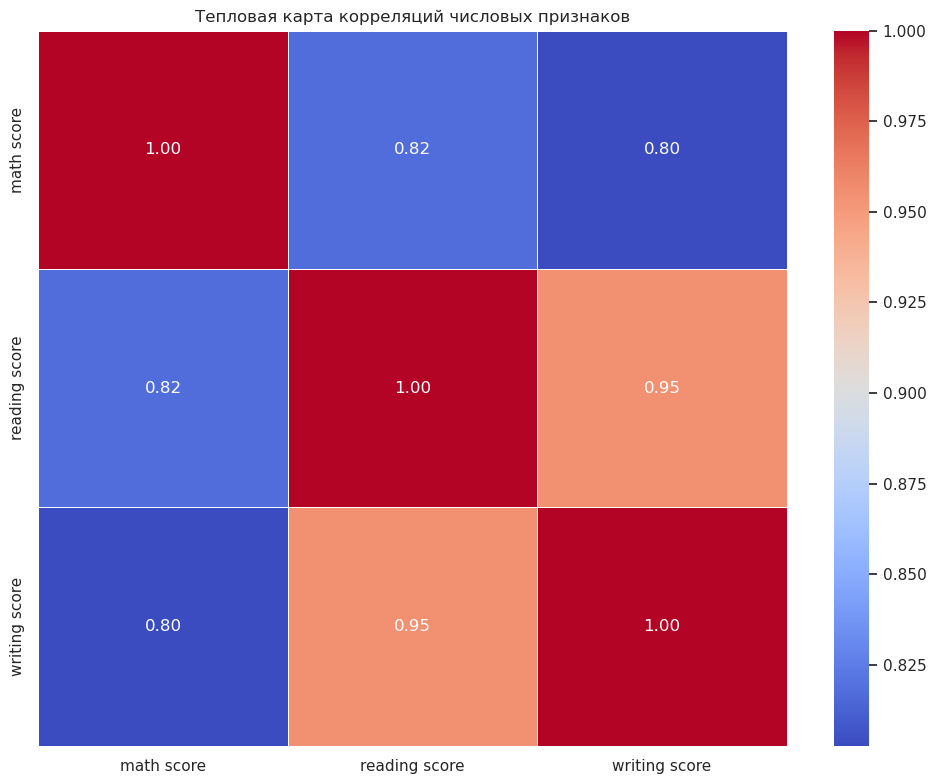

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Тепловая карта корреляций числовых признаков")
plt.tight_layout()
plt.show()

In [11]:
print("Средние баллы по полу:")
print(df.groupby("gender")[["math score", "reading score", "writing score"]].mean())
print("Средние баллы по уровню образования родителей:")
print(df.groupby("parental level of education")[["math score", "reading score", "writing score"]].mean())
print("Средние баллы по этническим группам:")
print(df.groupby("race/ethnicity")[["math score", "reading score", "writing score"]].mean())
print("Корреляционная матрица числовых признаков:")
print(df[num_cols].corr())

Средние баллы по полу:
        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203
Средние баллы по уровню образования родителей:
                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268
Средние баллы по этническим группам:
                math score  reading score  writing score
race/ethnicity                                          
group A          61.629